# 04 — Análisis de los barridos completos (E1 y E2)

Lee `runs.csv` de las corridas completas (`informe_data/final/e1/` y `informe_data/final/e2/`) y genera
tablas (CSV y `.tex`) en `informe_data/final/tables/` y figuras (PDF y PNG, 300 dpi) en
`informe_data/final/figs/`. **No vuelve a ejecutar los experimentos.**

Reglas que sigue este notebook:
- Solo se describe lo que muestran los datos; no hay conclusiones sobre "ventaja cuántica".
- El ajuste de la escala `s` (modo `scale_tuned`) es una **extensión propia**, motivada por
  Shaydulin & Wild (2022) y Flórez et al. (2025). **No es parte del protocolo de Kakavand**, que solo ajusta `C`
  (modo `kakavand`, `s = 1`).
- Todo proviene de simulación (statevector); la profundidad del HHL simulado **no** es evidencia de aceleración
  (el operador `e^{iFt}` se construye clásicamente).
- Los 25 pares (semilla × pliegue externo) comparten datos entre sí (los conjuntos de entrenamiento se solapan entre
  pliegues y entre semillas): **los p-valores de Wilcoxon son optimistas** y se dan solo como referencia descriptiva.

In [1]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FINAL = ROOT / "informe_data" / "final"
E1_DIR = Path(os.environ.get("E1_DIR", FINAL / "e1"))
E2_DIR = Path(os.environ.get("E2_DIR", FINAL / "e2"))
OUT = Path(os.environ.get("OUT_DIR", FINAL))
EXPECTED_E1 = int(os.environ.get("EXPECTED_E1", 144))   # 2 N x 4 n_c x 3 gamma x 2 modos x 3 semillas
EXPECTED_E2 = int(os.environ.get("EXPECTED_E2", 600))   # 3 datasets x 5 semillas x 5 pliegues x 4 kernels x 2 modos
TABLES, FIGS = OUT / "tables", OUT / "figs"
TABLES.mkdir(parents=True, exist_ok=True); FIGS.mkdir(parents=True, exist_ok=True)
print("E1:", E1_DIR, "\nE2:", E2_DIR, "\nSalida:", OUT)

# Paleta Okabe-Ito (apta para daltónicos); además se usan marcadores / rellenos distintos para escala de grises
COL = {"azul": "#0072B2", "naranja": "#E69F00", "verde": "#009E73", "bermellon": "#D55E00",
       "celeste": "#56B4E9", "rosa": "#CC79A7", "gris": "#7F7F7F"}
plt.rcParams.update({"font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9, "xtick.labelsize": 9,
                     "ytick.labelsize": 9, "legend.fontsize": 9, "axes.grid": True, "grid.alpha": 0.3,
                     "savefig.dpi": 300, "pdf.fonttype": 42, "figure.dpi": 110})
MAX_W = 6.0

def save_fig(fig, name):
    assert fig.get_size_inches()[0] <= MAX_W + 1e-9, "figura más ancha que 6 pulgadas"
    fig.savefig(FIGS / f"{name}.pdf")
    fig.savefig(FIGS / f"{name}.png", dpi=300)
    print("figura:", name)

def tex_escape(s):
    s = str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("_", r"\_"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#")]:
        s = s.replace(a, b)
    return s.replace("±", r"$\pm$")

def write_table(df, name, tex_header=None, align=None):
    # CSV con encabezados planos; .tex: solo tabular con \hline (sin booktabs, sin caption)
    df.to_csv(TABLES / f"{name}.csv", index=False, encoding="utf-8")
    hdr = tex_header or [tex_escape(c) for c in df.columns]
    align = align or ("l" * 1 + "c" * (df.shape[1] - 1))
    lines = [r"\begin{tabular}{" + align + "}", r"\hline", " & ".join(hdr) + r" \\", r"\hline"]
    for _, r in df.iterrows():
        lines.append(" & ".join(tex_escape(v) for v in r.values) + r" \\")
    lines += [r"\hline", r"\end{tabular}"]
    (TABLES / f"{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("tabla:", name, df.shape)

E1: C:\Users\marce\Documents\Universidad\12° Semestre\Computacion cuántica\Experimentos\informe_data\final\e1 
E2: C:\Users\marce\Documents\Universidad\12° Semestre\Computacion cuántica\Experimentos\informe_data\final\e2 
Salida: C:\Users\marce\Documents\Universidad\12° Semestre\Computacion cuántica\Experimentos\informe_data\final


## 1. E1 — HHL sobre LS-SVM: verificación de integridad y agregación

In [2]:
e1 = pd.read_csv(E1_DIR / "runs.csv")
K1 = ["N", "n_clock", "gamma", "mode", "seed"]
M1 = ["kappa", "n_total_qubits", "fidelity", "success_prob", "acc_hhl", "acc_classical", "agreement",
      "depth_pre", "depth_post", "cx_count", "wall_time_s", "imag_residual"]
print("filas E1:", len(e1), "(esperadas:", EXPECTED_E1, ")")
assert len(e1) == EXPECTED_E1
assert not e1.duplicated(K1).any(), "claves duplicadas"
assert not e1[M1].isna().any().any(), "NaN en métricas"
print("combinaciones por (N, n_c, gamma, mode):", e1.groupby(K1[:4]).size().unique(), "semillas:", sorted(e1.seed.unique()))
print("max |Im(x_hhl)| tras alinear la fase global:", e1.imag_residual.max())

# Diagnóstico derivado (no es una métrica del barrido): menor autovalor en unidades de la resolución del reloj.
# k_min = min|lambda| * t * 2^n_c / (2 pi). Si k_min < 1, ese autovalor cae en k = 0 y no recibe rotación.
lam = e1["eigenvalues"].apply(json.loads)
e1["k_min"] = lam.apply(lambda v: min(abs(x) for x in v)) * e1["t"] * 2.0 ** e1["n_clock"] / (2 * np.pi)

filas E1: 144 (esperadas: 144 )
combinaciones por (N, n_c, gamma, mode): [3] semillas: [np.int64(0), np.int64(1), np.int64(2)]
max |Im(x_hhl)| tras alinear la fase global: 7.480568464818028e-11


In [3]:
G1 = ["N", "n_clock", "gamma", "mode"]
E1_METRICS = ["kappa", "n_total_qubits", "fidelity", "success_prob", "acc_hhl", "acc_classical",
              "agreement", "depth_post", "cx_count"]
agg = e1.groupby(G1)[E1_METRICS].agg(["median", "min", "max"])
agg.columns = [f"{m}_{s}" for m, s in agg.columns]
agg = agg.reset_index()
agg.insert(4, "n_semillas", e1.groupby(G1).seed.nunique().values)
agg.to_csv(TABLES / "e1_tabla_completa.csv", index=False)       # versión numérica completa
print("tabla completa:", agg.shape)

def fmt(r, m, d):
    if d == 0 and r[f"{m}_min"] == r[f"{m}_max"]:
        return f"{r[f'{m}_median']:.0f}"
    return f"{r[f'{m}_median']:.{d}f} [{r[f'{m}_min']:.{d}f}, {r[f'{m}_max']:.{d}f}]"

def build(cols):
    out = pd.DataFrame({"N": agg.N, "n_c": agg.n_clock, "gamma": agg.gamma.map(lambda g: f"{g:g}"), "modo": agg["mode"]})
    for plain, m, d in cols:
        out[plain] = agg.apply(lambda r: fmt(r, m, d), axis=1)
    return out

cal = build([("kappa", "kappa", 1), ("fidelidad", "fidelity", 3), ("p_exito", "success_prob", 4),
             ("acc_hhl", "acc_hhl", 2), ("acc_clasica", "acc_classical", 2), ("concordancia", "agreement", 2)])
write_table(cal, "e1_calidad",
            tex_header=["$N$", "$n_c$", r"$\gamma$", "modo", r"$\kappa$", "fidelidad", r"$p_{\mathrm{\acute{e}xito}}$",
                        "acc. HHL", r"acc. cl\'asica", "concordancia"],
            align="cclllllll".replace("cclllllll", "ccclllccc"))
rec = build([("qubits", "n_total_qubits", 0), ("prof_post", "depth_post", 0), ("cx", "cx_count", 0)])
write_table(rec, "e1_recursos",
            tex_header=["$N$", "$n_c$", r"$\gamma$", "modo", "qubits", "profundidad (transp.)", "cx"],
            align="ccclccc")
print("Cada celda: mediana [mín, máx] sobre las semillas.")
cal.head(12)

tabla completa: (48, 32)
tabla: e1_calidad (48, 10)
tabla: e1_recursos (48, 7)
Cada celda: mediana [mín, máx] sobre las semillas.


,N,n_c,gamma,modo,kappa,fidelidad,p_exito,acc_hhl,acc_clasica,concordancia
0,3,3,0.1,exact,"273.7 [236.3, 282.8]","0.009 [0.008, 0.013]","0.1086 [0.1036, 0.1190]","0.82 [0.65, 0.85]","0.82 [0.65, 0.88]","0.95 [0.93, 1.00]"
1,3,3,0.1,trotter,"273.7 [236.3, 282.8]","0.016 [0.012, 0.016]","0.1145 [0.1047, 0.1164]","0.82 [0.65, 0.85]","0.82 [0.65, 0.88]","0.95 [0.93, 1.00]"
2,3,3,1,exact,"54.3 [46.0, 56.4]","0.006 [0.005, 0.007]","0.1000 [0.0994, 0.1093]","0.82 [0.65, 0.88]","0.82 [0.65, 0.88]","0.95 [0.90, 1.00]"
3,3,3,1,trotter,"54.3 [46.0, 56.4]","0.014 [0.010, 0.015]","0.1020 [0.0975, 0.1046]","0.82 [0.65, 0.88]","0.82 [0.65, 0.88]","0.95 [0.90, 1.00]"
4,3,3,10,exact,"41.5 [35.1, 43.1]","0.006 [0.005, 0.008]","0.1001 [0.0994, 0.1080]","0.82 [0.65, 0.88]","0.82 [0.65, 0.88]","0.95 [0.90, 1.00]"
5,3,3,10,trotter,"41.5 [35.1, 43.1]","0.014 [0.010, 0.015]","0.1021 [0.0974, 0.1035]","0.82 [0.65, 0.88]","0.82 [0.65, 0.88]","0.95 [0.90, 1.00]"
6,3,4,0.1,exact,"273.7 [236.3, 282.8]","0.031 [0.031, 0.033]","0.1201 [0.1190, 0.1252]","0.80 [0.65, 0.85]","0.82 [0.65, 0.88]","0.97 [0.93, 1.00]"
7,3,4,0.1,trotter,"273.7 [236.3, 282.8]","0.026 [0.012, 0.032]","0.1111 [0.0845, 0.1157]","0.82 [0.65, 0.88]","0.82 [0.65, 0.88]","0.95 [0.90, 1.00]"
8,3,4,1,exact,"54.3 [46.0, 56.4]","0.018 [0.017, 0.035]","0.0189 [0.0185, 0.0225]","0.80 [0.65, 0.88]","0.82 [0.65, 0.88]","0.97 [0.90, 1.00]"
9,3,4,1,trotter,"54.3 [46.0, 56.4]","0.068 [0.047, 0.070]","0.0197 [0.0174, 0.0213]","0.82 [0.65, 0.85]","0.82 [0.65, 0.88]","0.95 [0.93, 1.00]"


figura: fig1_fidelidad_vs_nc


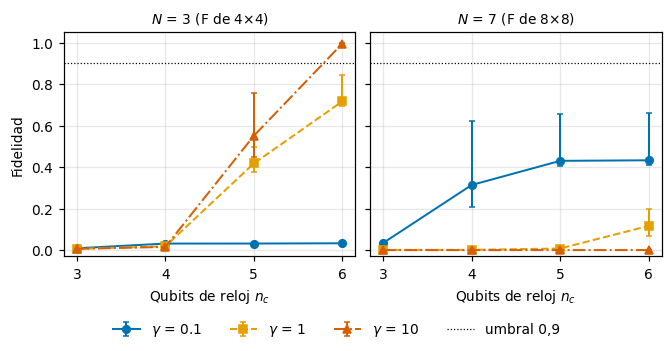

In [4]:
# --- Figura 1: fidelidad vs n_c, una línea por gamma, un panel por N (modo exact) ---
ex = e1[e1["mode"] == "exact"]
Ns, gammas = sorted(ex.N.unique()), sorted(ex.gamma.unique())
sty = [dict(color=COL["azul"], marker="o", ls="-"), dict(color=COL["naranja"], marker="s", ls="--"),
       dict(color=COL["bermellon"], marker="^", ls="-."), dict(color=COL["verde"], marker="D", ls=":")]
fig, axes = plt.subplots(1, len(Ns), figsize=(6, 3.1), sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)
for ax, N in zip(axes, Ns):
    for i, g in enumerate(gammas):
        s = ex[(ex.N == N) & (ex.gamma == g)].groupby("n_clock").fidelity.agg(["median", "min", "max"])
        ax.errorbar(s.index, s["median"], yerr=[s["median"] - s["min"], s["max"] - s["median"]],
                    capsize=2, lw=1.3, ms=5, label=rf"$\gamma$ = {g:g}", **sty[i % len(sty)])
    ax.axhline(0.9, color="k", lw=0.8, ls=":")
    ax.set_title(rf"$N$ = {N} (F de {N+1 if (N+1)&N==0 else 1<<int(np.ceil(np.log2(N+1)))}×{N+1 if (N+1)&N==0 else 1<<int(np.ceil(np.log2(N+1)))})")
    ax.set_xlabel(r"Qubits de reloj $n_c$"); ax.set_xticks(sorted(ex.n_clock.unique())); ax.set_ylim(-0.03, 1.05)
axes[0].set_ylabel("Fidelidad")
h, l = axes[0].get_legend_handles_labels()
h.append(Line2D([], [], color="k", lw=0.8, ls=":")); l.append("umbral 0,9")
fig.legend(h, l, loc="outside lower center", ncol=len(h), frameon=False)
save_fig(fig, "fig1_fidelidad_vs_nc"); plt.show()

figura: fig2_cx_vs_nc


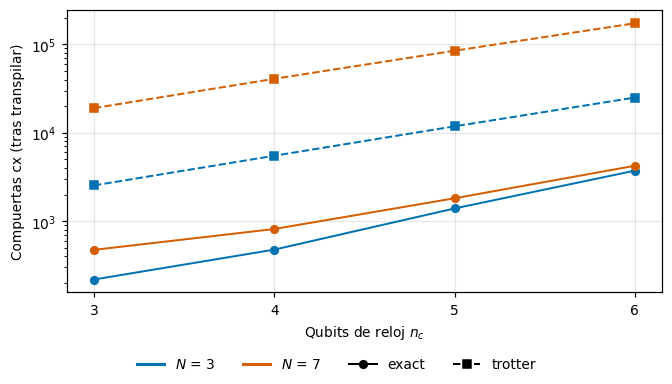

In [5]:
# --- Figura 2: cx_count (log) vs n_c; líneas por N; exact vs trotter (mediana y mín-máx sobre gamma x semillas) ---
fig, ax = plt.subplots(figsize=(6, 3.4), constrained_layout=True)
colN = {n: c for n, c in zip(sorted(e1.N.unique()), [COL["azul"], COL["bermellon"], COL["verde"]])}
stm = {"exact": dict(marker="o", ls="-"), "trotter": dict(marker="s", ls="--")}
for N in sorted(e1.N.unique()):
    for mode in ["exact", "trotter"]:
        s = e1[(e1.N == N) & (e1["mode"] == mode)].groupby("n_clock").cx_count.agg(["median", "min", "max"])
        ax.errorbar(s.index, s["median"], yerr=[s["median"] - s["min"], s["max"] - s["median"]],
                    capsize=2, lw=1.3, ms=5, color=colN[N], **stm[mode])
ax.set_yscale("log"); ax.set_xlabel(r"Qubits de reloj $n_c$"); ax.set_ylabel("Compuertas cx (tras transpilar)")
ax.set_xticks(sorted(e1.n_clock.unique()))
hN = [Line2D([], [], color=colN[n], lw=2, label=rf"$N$ = {n}") for n in colN]
hM = [Line2D([], [], color="k", label=m, **stm[m], ms=5, lw=1.3) for m in stm]
fig.legend(hN + hM, [h.get_label() for h in hN + hM], loc="outside lower center", ncol=4, frameon=False)
save_fig(fig, "fig2_cx_vs_nc"); plt.show()

In [6]:
# --- Cuántas configuraciones alcanzan fidelidad >= 0.9 y bajo qué combinación de gamma / kappa / n_c ---
e1["fid90"] = e1.fidelity >= 0.9
cfg = (e1.groupby(G1).agg(n_semillas=("seed", "nunique"), semillas_fid90=("fid90", "sum"),
                          fid_mediana=("fidelity", "median"), kappa_mediana=("kappa", "median"),
                          kappa_min=("kappa", "min"), kappa_max=("kappa", "max"),
                          kmin_mediana=("k_min", "median")).reset_index())
cfg["mediana_fid90"] = cfg.fid_mediana >= 0.9
cfg.to_csv(TABLES / "e1_fid90_por_config.csv", index=False)
print(f"Corridas individuales con fidelidad >= 0.9: {int(e1.fid90.sum())} de {len(e1)}")
print(f"Configuraciones (N, n_c, gamma, modo; mediana sobre semillas) con fidelidad >= 0.9: "
      f"{int(cfg.mediana_fid90.sum())} de {len(cfg)}")
print("\nPor modo (corridas):\n", e1.groupby("mode").fid90.agg(["sum", "count"]).to_string())
print("\nCorridas con fid >= 0.9 por (N, gamma, n_c), modo exact:")
print(e1[e1["mode"] == "exact"].pivot_table(index=["N", "gamma"], columns="n_clock", values="fid90", aggfunc="sum").to_string())
print("\nCorridas con fid >= 0.9 por (N, gamma, n_c), modo trotter:")
print(e1[e1["mode"] == "trotter"].pivot_table(index=["N", "gamma"], columns="n_clock", values="fid90", aggfunc="sum").to_string())
print("\nkappa (mín-máx) de las corridas con fid >= 0.9 vs el resto:")
print(e1.groupby("fid90").kappa.agg(["min", "median", "max"]).to_string())
print("\nn_c de las corridas con fid >= 0.9:", e1[e1.fid90].n_clock.value_counts().sort_index().to_dict())
print("\nDiagnóstico k_min (menor autovalor / resolución del reloj), mediana por fid90:")
print(e1.groupby("fid90").k_min.agg(["min", "median", "max"]).to_string())
r = stats.spearmanr(e1.k_min, e1.fidelity)
print(f"Spearman(k_min, fidelidad) sobre las {len(e1)} corridas: rho = {r.statistic:.3f} (p = {r.pvalue:.2g})")
print("Fidelidad con k_min < 1 vs >= 1:\n", e1.groupby(e1.k_min < 1).fidelity.agg(["count", "median", "max"]).to_string())
cfg[cfg.mediana_fid90]

Corridas individuales con fidelidad >= 0.9: 3 de 144
Configuraciones (N, n_c, gamma, modo; mediana sobre semillas) con fidelidad >= 0.9: 1 de 48

Por modo (corridas):
          sum  count
mode               
exact      3     72
trotter    0     72

Corridas con fid >= 0.9 por (N, gamma, n_c), modo exact:
n_clock  3  4  5  6
N gamma            
3 0.1    0  0  0  0
  1.0    0  0  0  0
  10.0   0  0  0  3
7 0.1    0  0  0  0
  1.0    0  0  0  0
  10.0   0  0  0  0

Corridas con fid >= 0.9 por (N, gamma, n_c), modo trotter:
n_clock  3  4  5  6
N gamma            
3 0.1    0  0  0  0
  1.0    0  0  0  0
  10.0   0  0  0  0
7 0.1    0  0  0  0
  1.0    0  0  0  0
  10.0   0  0  0  0

kappa (mín-máx) de las corridas con fid >= 0.9 vs el resto:
             min      median          max
fid90                                    
False  35.050553  197.342532  1422.984158
True   35.050553   41.527343    43.099870

n_c de las corridas con fid >= 0.9: {6: 3}

Diagnóstico k_min (menor autovalor / res

,N,n_clock,gamma,mode,n_semillas,semillas_fid90,fid_mediana,kappa_mediana,kappa_min,kappa_max,kmin_mediana,mediana_fid90
22,3,6,10.0,exact,3,3,0.994323,41.527343,35.050553,43.09987,0.746496,True


In [7]:
# Resumen adicional E1: clasificación y recursos
print("acc_hhl - acc_classical (puntos porcentuales), por modo:")
print(((e1.acc_hhl - e1.acc_classical) * 100).groupby(e1["mode"]).describe().to_string())
print("\nconcordancia HHL-clásico (agreement): mediana por modo y fid90")
print(e1.groupby(["mode", "fid90"]).agreement.agg(["count", "median", "min"]).to_string())
print("\nprob. de éxito: min / mediana / max =", e1.success_prob.min(), e1.success_prob.median(), e1.success_prob.max())
print("tiempo de pared (s): mediana por modo y N")
print(e1.groupby(["N", "mode"]).wall_time_s.median().to_string(), "\ntotal (s):", e1.wall_time_s.sum())

acc_hhl - acc_classical (puntos porcentuales), por modo:
         count      mean        std   min  25%  50%  75%  max
mode                                                         
exact     72.0 -0.486111   1.491696  -2.5 -2.5  0.0  0.0  5.0
trotter   72.0 -3.680556  14.970465 -92.5 -2.5  0.0  0.0  5.0

concordancia HHL-clásico (agreement): mediana por modo y fid90
               count  median    min
mode    fid90                      
exact   False     69   1.000  0.900
        True       3   1.000  1.000
trotter False     72   0.975  0.075

prob. de éxito: min / mediana / max = 0.0024435519743702 0.051325994330891606 0.4728043027057338
tiempo de pared (s): mediana por modo y N
N  mode   
3  exact       0.173587
   trotter     0.863449
7  exact       1.194849
   trotter    16.724808 
total (s): 1394.4085323810577


## 2. E2 — QSVC vs SVC: verificación de integridad

In [8]:
df = pd.read_csv(E2_DIR / "runs.csv")
K2 = ["dataset", "kernel", "mode", "seed", "outer_fold"]
M2 = ["balanced_accuracy", "accuracy", "best_C", "best_s", "n_kernel_evals", "kernel_time_s", "fit_time_s"]
print("filas E2:", len(df), "(esperadas:", EXPECTED_E2, ")")
assert len(df) == EXPECTED_E2
assert not df.duplicated(K2).any(), "claves duplicadas"
assert not df[M2].isna().any().any(), "NaN en métricas"
cnt = df.groupby(["dataset", "kernel", "mode"]).size()
PER = EXPECTED_E2 // 24          # 25 = 5 semillas x 5 pliegues en el barrido completo
assert (cnt == PER).all(), cnt
DS = ["breast_cancer", "banknote", "haberman"]
KS = ["linear", "rbf", "zzfm", "rot2dof"]
MODES = ["kakavand", "scale_tuned"]
assert set(df.dataset) == set(DS) and set(df.kernel) == set(KS) and set(df["mode"]) == set(MODES)
print(f"{PER} combinaciones (semilla x pliegue) por dataset x kernel x modo: OK")

# El kernel lineal no usa s: sus filas deben ser idénticas en ambos modos
lin = df[df.kernel == "linear"].pivot_table(index=["dataset", "seed", "outer_fold"], columns="mode",
                                           values=["balanced_accuracy", "best_C", "best_s"])
for m in ["balanced_accuracy", "best_C", "best_s"]:
    assert np.array_equal(lin[(m, "kakavand")].values, lin[(m, "scale_tuned")].values), m
print("lineal: filas idénticas en ambos modos (balanced_accuracy, best_C, best_s): OK")

filas E2: 600 (esperadas: 600 )
25 combinaciones (semilla x pliegue) por dataset x kernel x modo: OK
lineal: filas idénticas en ambos modos (balanced_accuracy, best_C, best_s): OK


## 3. E2 — tabla principal y comparación pareada

In [9]:
LAB = {"linear": "lineal", "rbf": "rbf", "zzfm": "zzfm", "rot2dof": "rot2dof"}
MLAB = {"kakavand": "s=1", "scale_tuned": "s ajustada"}
df["ba"] = df.balanced_accuracy * 100

# Tabla principal: media ± desviación (ddof=1) de la exactitud balanceada (%), 25 combinaciones semilla x pliegue
g = df.groupby(["dataset", "kernel", "mode"]).ba.agg(["mean", "std", "median", "min", "max", "count"]).reset_index()
g.to_csv(TABLES / "e2_principal_numerico.csv", index=False)
cols = [("linear", "kakavand")] + [(k, m) for k in ["rbf", "zzfm", "rot2dof"] for m in MODES]
main = pd.DataFrame({"dataset": DS})
for k, m in cols:
    name = "lineal" if k == "linear" else f"{LAB[k]} ({MLAB[m]})"
    main[name] = [f"{g[(g.dataset == d) & (g.kernel == k) & (g['mode'] == m)]['mean'].item():.2f} ± "
                  f"{g[(g.dataset == d) & (g.kernel == k) & (g['mode'] == m)]['std'].item():.2f}" for d in DS]
write_table(main, "e2_principal",
            tex_header=["dataset", "lineal", r"rbf ($s$=1)", r"rbf ($s$ aj.)", r"zzfm ($s$=1)", r"zzfm ($s$ aj.)",
                        r"rot2dof ($s$=1)", r"rot2dof ($s$ aj.)"], align="lccccccc")
print("Exactitud balanceada (%), media ± desv. sobre 25 (semilla x pliegue). 'lineal' no usa s (idéntico en ambos modos).")
main

tabla: e2_principal (3, 8)
Exactitud balanceada (%), media ± desv. sobre 25 (semilla x pliegue). 'lineal' no usa s (idéntico en ambos modos).


,dataset,lineal,rbf (s=1),rbf (s ajustada),zzfm (s=1),zzfm (s ajustada),rot2dof (s=1),rot2dof (s ajustada)
0,breast_cancer,95.45 ± 2.04,95.07 ± 2.13,95.10 ± 2.25,49.50 ± 2.70,85.40 ± 2.43,53.10 ± 2.33,73.14 ± 4.36
1,banknote,98.32 ± 1.83,99.88 ± 0.61,99.76 ± 0.83,58.91 ± 7.02,99.65 ± 0.88,67.44 ± 4.83,71.10 ± 4.63
2,haberman,50.90 ± 3.00,56.68 ± 4.04,56.74 ± 4.38,50.69 ± 5.81,56.31 ± 5.20,50.00 ± 0.00,50.07 ± 0.37


In [10]:
TOL = 1e-12
piv = df.pivot_table(index=["dataset", "mode", "seed", "outer_fold"], columns="kernel", values="balanced_accuracy")
rows = []
for d in DS:
    for m in MODES:
        sub = piv.loc[(d, m)]
        for k in ["zzfm", "rot2dof"]:
            diff = (sub[k] - sub["rbf"])
            assert len(diff) == PER
            w, t, l = int((diff > TOL).sum()), int((diff.abs() <= TOL).sum()), int((diff < -TOL).sum())
            try:
                wil = stats.wilcoxon(diff.values, zero_method="wilcox", alternative="two-sided")
                stat, p = float(wil.statistic), float(wil.pvalue)
            except ValueError:                                   # todas las diferencias son cero
                stat, p = np.nan, np.nan
            ds = diff.groupby(level="seed").mean()               # media de los 5 pliegues por semilla
            sw, st, sl = int((ds > TOL).sum()), int((ds.abs() <= TOL).sum()), int((ds < -TOL).sum())
            rows.append(dict(dataset=d, modo=m, kernel=k, dif_media_pp=diff.mean() * 100, dif_mediana_pp=diff.median() * 100,
                             ganados=w, empatados=t, perdidos=l, wilcoxon_W=stat, p_valor=p,
                             semillas_gana=sw, semillas_empata=st, semillas_pierde=sl))
par = pd.DataFrame(rows)
par.to_csv(TABLES / "e2_pareada_numerico.csv", index=False)
parf = pd.DataFrame({"dataset": par.dataset, "modo": par.modo.map(MLAB), "kernel vs rbf": par.kernel,
                     "dif. media (pp)": par.dif_media_pp.map(lambda x: f"{x:+.2f}"),
                     "G/E/P (25 pares)": par.apply(lambda r: f"{r.ganados}/{r.empatados}/{r.perdidos}", axis=1),
                     "Wilcoxon p": par.p_valor.map(lambda p: "--" if np.isnan(p) else (f"{p:.3f}" if p >= 0.001 else "<0.001")),
                     "semillas G/E/P (5)": par.apply(lambda r: f"{r.semillas_gana}/{r.semillas_empata}/{r.semillas_pierde}", axis=1)})
write_table(parf, "e2_pareada",
            tex_header=["dataset", "modo", "kernel vs rbf", "dif. media (pp)", "G/E/P (25 pares)", "Wilcoxon $p$", "semillas G/E/P (5)"],
            align="llllccc")
print("pp = puntos porcentuales; G/E/P = ganados/empatados/perdidos del kernel cuántico frente a rbf (mismo modo, misma semilla y pliegue).")
print("ATENCIÓN: los pliegues comparten datos; los p-valores son optimistas (sin corrección por comparaciones múltiples).")
parf

tabla: e2_pareada (12, 7)
pp = puntos porcentuales; G/E/P = ganados/empatados/perdidos del kernel cuántico frente a rbf (mismo modo, misma semilla y pliegue).
ATENCIÓN: los pliegues comparten datos; los p-valores son optimistas (sin corrección por comparaciones múltiples).


,dataset,modo,kernel vs rbf,dif. media (pp),G/E/P (25 pares),Wilcoxon p,semillas G/E/P (5)
0,breast_cancer,s=1,zzfm,-45.56,0/0/25,<0.001,0/0/5
1,breast_cancer,s=1,rot2dof,-41.97,0/0/25,<0.001,0/0/5
2,breast_cancer,s ajustada,zzfm,-9.71,0/0/25,<0.001,0/0/5
3,breast_cancer,s ajustada,rot2dof,-21.96,0/0/25,<0.001,0/0/5
4,banknote,s=1,zzfm,-40.97,0/0/25,<0.001,0/0/5
5,banknote,s=1,rot2dof,-32.44,0/0/25,<0.001,0/0/5
6,banknote,s ajustada,zzfm,-0.11,2/20/3,0.684,2/1/2
7,banknote,s ajustada,rot2dof,-28.66,0/0/25,<0.001,0/0/5
8,haberman,s=1,zzfm,-5.99,2/0/23,<0.001,0/0/5
9,haberman,s=1,rot2dof,-6.68,2/0/23,<0.001,0/0/5


## 4. E2 — efecto de `s` (extensión propia; no es parte del protocolo de Kakavand)

In [11]:
pv = df.pivot_table(index=["dataset", "kernel", "seed", "outer_fold"], columns="mode", values="balanced_accuracy")
dd = ((pv["scale_tuned"] - pv["kakavand"]) * 100).rename("delta_pp").reset_index()
rows = []
for d in DS:
    for k in KS:
        x = dd[(dd.dataset == d) & (dd.kernel == k)].delta_pp
        w, t, l = int((x > TOL * 100).sum()), int((x.abs() <= TOL * 100).sum()), int((x < -TOL * 100).sum())
        try:
            p = float(stats.wilcoxon(x.values, zero_method="wilcox").pvalue)
        except ValueError:
            p = np.nan
        rows.append(dict(dataset=d, kernel=k, n=len(x), delta_media_pp=x.mean(), delta_mediana_pp=x.median(),
                         delta_min_pp=x.min(), delta_max_pp=x.max(), mejora=w, empata=t, empeora=l, wilcoxon_p=p))
efs = pd.DataFrame(rows)
efs.to_csv(TABLES / "e2_efecto_s_numerico.csv", index=False)
efsf = pd.DataFrame({"dataset": efs.dataset, "kernel": efs.kernel,
                     "Δ media (pp)": efs.delta_media_pp.map(lambda x: f"{x:+.2f}"),
                     "Δ mediana (pp)": efs.delta_mediana_pp.map(lambda x: f"{x:+.2f}"),
                     "mejora/empata/empeora": efs.apply(lambda r: f"{r.mejora}/{r.empata}/{r.empeora}", axis=1),
                     "Wilcoxon p": efs.wilcoxon_p.map(lambda p: "--" if np.isnan(p) else (f"{p:.3f}" if p >= 0.001 else "<0.001"))})
write_table(efsf, "e2_efecto_s", tex_header=["dataset", "kernel", r"$\Delta$ media (pp)", r"$\Delta$ mediana (pp)",
                                             "mejora/empata/empeora", "Wilcoxon $p$"], align="llcccc")
print("Δ = exactitud balanceada (scale_tuned) − (kakavand, s=1), por pares (semilla, pliegue). Los p-valores son optimistas.")
efsf

tabla: e2_efecto_s (12, 6)
Δ = exactitud balanceada (scale_tuned) − (kakavand, s=1), por pares (semilla, pliegue). Los p-valores son optimistas.


C:\Users\marce\Documents\Universidad\12° Semestre\Computacion cuántica\Experimentos\.venv\Lib\site-packages\scipy\stats\_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
C:\Users\marce\Documents\Universidad\12° Semestre\Computacion cuántica\Experimentos\.venv\Lib\site-packages\scipy\stats\_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
C:\Users\marce\Documents\Universidad\12° Semestre\Computacion cuántica\Experimentos\.venv\Lib\site-packages\scipy\stats\_wilcoxon.py:181: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,dataset,kernel,Δ media (pp),Δ mediana (pp),mejora/empata/empeora,Wilcoxon p
0,breast_cancer,linear,+0.00,+0.00,0/25/0,--
1,breast_cancer,rbf,+0.04,+0.00,7/7/11,0.913
2,breast_cancer,zzfm,+35.89,+35.98,25/0/0,<0.001
3,breast_cancer,rot2dof,+20.05,+20.23,25/0/0,<0.001
4,banknote,linear,+0.00,+0.00,0/25/0,--
5,banknote,rbf,-0.12,+0.00,0/24/1,0.317
6,banknote,zzfm,+40.74,+41.08,25/0/0,<0.001
7,banknote,rot2dof,+3.67,+3.03,17/4/4,0.003
8,haberman,linear,+0.00,+0.00,0/25/0,--
9,haberman,rbf,+0.06,+0.00,12/5/8,0.723


In [12]:
# Distribución de best_s elegidos (modo scale_tuned) y comprobación de que el RBF también recibe el ajuste de s
st = df[df["mode"] == "scale_tuned"]
S_GRID = sorted(df.best_s.unique())
dist = st.groupby(["dataset", "kernel"]).best_s.value_counts().unstack(fill_value=0).reindex(columns=S_GRID, fill_value=0)
dist = dist.reindex(pd.MultiIndex.from_product([DS, KS], names=["dataset", "kernel"]))
dist_pct = (dist.div(dist.sum(axis=1), axis=0) * 100).round(1)
dist_out = dist.reset_index(); dist_out.columns = ["dataset", "kernel"] + [f"s={s:g}" for s in S_GRID]
dist_out.to_csv(TABLES / "e2_best_s_conteos.csv", index=False)
dist_f = dist_out.copy()
for c in dist_f.columns[2:]:
    dist_f[c] = dist_f[c].astype(int).astype(str)
write_table(dist_f, "e2_best_s", tex_header=["dataset", "kernel"] + [rf"$s$={s:g}" for s in S_GRID], align="llccccc")
print("best_s elegido por la CV interna (conteo sobre 25 pares):")
print(dist_out.to_string(index=False))

kak = df[df["mode"] == "kakavand"]
print("\nmodo kakavand: valores de best_s =", sorted(kak.best_s.unique()), "(debe ser solo 1.0)")
print("modo scale_tuned, valores de best_s por kernel:", st.groupby("kernel").best_s.apply(lambda s: sorted(s.unique())).to_dict())

# Evidencia de que el RBF recibe el mismo ajuste que los kernels cuánticos: nº de entradas de Gram (se calcula una por s)
ne = df.pivot_table(index=["dataset", "kernel", "seed", "outer_fold"], columns="mode", values="n_kernel_evals")
ratio = (ne["scale_tuned"] / ne["kakavand"]).groupby("kernel").agg(["min", "max"])
print("\nrazón n_kernel_evals scale_tuned / kakavand por kernel (5 valores de s -> 5 esperado; lineal 1):")
print(ratio.to_string())

tabla: e2_best_s (12, 7)
best_s elegido por la CV interna (conteo sobre 25 pares):
      dataset  kernel  s=0.1  s=0.25  s=0.5  s=1  s=2
breast_cancer  linear      0       0      0   25    0
breast_cancer     rbf      9       4     10    1    1
breast_cancer    zzfm     25       0      0    0    0
breast_cancer rot2dof      0      20      5    0    0
     banknote  linear      0       0      0   25    0
     banknote     rbf      0       2      1   18    4
     banknote    zzfm     25       0      0    0    0
     banknote rot2dof      0       0      2    4   19
     haberman  linear      0       0      0   25    0
     haberman     rbf      0       1     15    3    6
     haberman    zzfm      7       7      7    3    1
     haberman rot2dof      0       1      4   20    0

modo kakavand: valores de best_s = [np.float64(1.0)] (debe ser solo 1.0)
modo scale_tuned, valores de best_s por kernel: {'linear': [np.float64(1.0)], 'rbf': [np.float64(0.1), np.float64(0.25), np.float64(0.5), np.

## 5. E2 — costo

In [13]:
cost = df.groupby(["dataset", "kernel", "mode"]).agg(n_kernel_evals_mediana=("n_kernel_evals", "median"),
                                                       kernel_time_s_mediana=("kernel_time_s", "median"),
                                                       fit_time_s_mediana=("fit_time_s", "median")).reset_index()
cost.to_csv(TABLES / "e2_costo_numerico.csv", index=False)
# El lineal es idéntico en ambos modos: se muestra una sola vez
lin_dup = cost[(cost.kernel == "linear") & (cost["mode"] == "scale_tuned")]
print("lineal scale_tuned vs kakavand: costo distinto solo por ruido de medición de tiempos:")
print(cost[cost.kernel == "linear"].to_string(index=False))
costf = cost[~((cost.kernel == "linear") & (cost["mode"] == "scale_tuned"))].copy()
costf["modo"] = costf.apply(lambda r: "--" if r.kernel == "linear" else MLAB[r["mode"]], axis=1)
costf["kernel"] = costf.kernel.map(LAB)
costf["order"] = costf.dataset.map({d: i for i, d in enumerate(DS)}) * 100 + costf.kernel.map({"lineal": 0, "rbf": 1, "zzfm": 2, "rot2dof": 3}) * 10 + (costf["mode"] == "scale_tuned")
costf = costf.sort_values("order")
cf = pd.DataFrame({"dataset": costf.dataset, "kernel": costf.kernel, "modo": costf.modo,
                   "n_kernel_evals": costf.n_kernel_evals_mediana.map(lambda x: f"{x:,.0f}".replace(",", " ")),
                   "t_kernel (s)": costf.kernel_time_s_mediana.map(lambda x: f"{x:.3f}"),
                   "t_ajuste (s)": costf.fit_time_s_mediana.map(lambda x: f"{x:.3f}")})
write_table(cf, "e2_costo", tex_header=["dataset", "kernel", "modo", "n\\_kernel\\_evals", "$t_{\\mathrm{kernel}}$ (s)", "$t_{\\mathrm{ajuste}}$ (s)"],
            align="lllccc")
print("Mediana por dataset x kernel x modo (25 pares). kernel_time_s es el tiempo de cálculo original aunque la matriz venga del caché.")
print("n_kernel_evals cuenta entradas de Gram (circuitos de fidelidad necesarios en hardware), no tiempo de simulación.")
cf

lineal scale_tuned vs kakavand: costo distinto solo por ruido de medición de tiempos:
      dataset kernel        mode  n_kernel_evals_mediana  kernel_time_s_mediana  fit_time_s_mediana
     banknote linear    kakavand                 43320.0                    0.0            0.027878
     banknote linear scale_tuned                 43320.0                    0.0            0.029642
breast_cancer linear    kakavand                155610.0                    0.0            0.112156
breast_cancer linear scale_tuned                155610.0                    0.0            0.105024
     haberman linear    kakavand                 45080.0                    0.0            0.103966
     haberman linear scale_tuned                 45080.0                    0.0            0.115807
tabla: e2_costo (21, 6)
Mediana por dataset x kernel x modo (25 pares). kernel_time_s es el tiempo de cálculo original aunque la matriz venga del caché.
n_kernel_evals cuenta entradas de Gram (circuitos de fidelida

,dataset,kernel,modo,n_kernel_evals,t_kernel (s),t_ajuste (s)
8,breast_cancer,lineal,--,155 610,0.000,0.112
10,breast_cancer,rbf,s=1,155 610,0.010,0.044
11,breast_cancer,rbf,s ajustada,778 050,0.028,0.222
14,breast_cancer,zzfm,s=1,155 610,1.635,0.150
15,breast_cancer,zzfm,s ajustada,778 050,8.336,0.427
12,breast_cancer,rot2dof,s=1,155 610,0.973,0.186
13,breast_cancer,rot2dof,s ajustada,778 050,5.108,0.365
0,banknote,lineal,--,43 320,0.000,0.028
2,banknote,rbf,s=1,43 320,0.000,0.026
3,banknote,rbf,s ajustada,216 600,0.006,0.125


## 6. E2 — figuras

figura: fig3_boxplot_balanced_accuracy


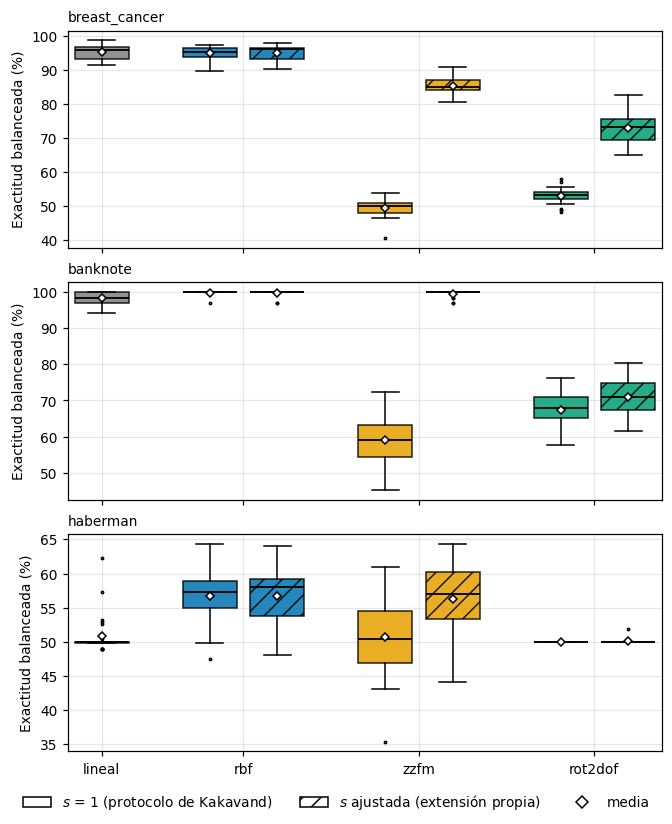

In [14]:
# --- Figura 3: boxplot de balanced_accuracy; un panel por dataset; kernels x modo ---
order = [("linear", "kakavand"), ("rbf", "kakavand"), ("rbf", "scale_tuned"), ("zzfm", "kakavand"), ("zzfm", "scale_tuned"),
         ("rot2dof", "kakavand"), ("rot2dof", "scale_tuned")]
pos = [0, 1.6, 2.6, 4.2, 5.2, 6.8, 7.8]
kcol = {"linear": COL["gris"], "rbf": COL["azul"], "zzfm": COL["naranja"], "rot2dof": COL["verde"]}
fig, axes = plt.subplots(len(DS), 1, figsize=(6, 7.4), sharex=True, constrained_layout=True)
for ax, d in zip(axes, DS):
    data = [df[(df.dataset == d) & (df.kernel == k) & (df["mode"] == m)].ba.values for k, m in order]
    bp = ax.boxplot(data, positions=pos, widths=0.8, patch_artist=True, showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=4),
                    medianprops=dict(color="k", lw=1.2), flierprops=dict(marker=".", markersize=3))
    for patch, (k, m) in zip(bp["boxes"], order):
        patch.set_facecolor(kcol[k]); patch.set_alpha(0.85); patch.set_edgecolor("k")
        patch.set_hatch("//" if m == "scale_tuned" else "")
    ax.set_title(d, loc="left"); ax.set_ylabel("Exactitud balanceada (%)")
ctr = [0, 2.1, 4.7, 7.3]
axes[-1].set_xticks(ctr); axes[-1].set_xticklabels(["lineal", "rbf", "zzfm", "rot2dof"])
hl = [Patch(facecolor="white", edgecolor="k", label=r"$s$ = 1 (protocolo de Kakavand)"),
      Patch(facecolor="white", edgecolor="k", hatch="//", label=r"$s$ ajustada (extensión propia)"),
      Line2D([], [], marker="D", color="w", markerfacecolor="white", markeredgecolor="k", label="media")]
fig.legend(handles=hl, loc="outside lower center", ncol=3, frameon=False)
save_fig(fig, "fig3_boxplot_balanced_accuracy"); plt.show()

figura: fig4_efecto_s


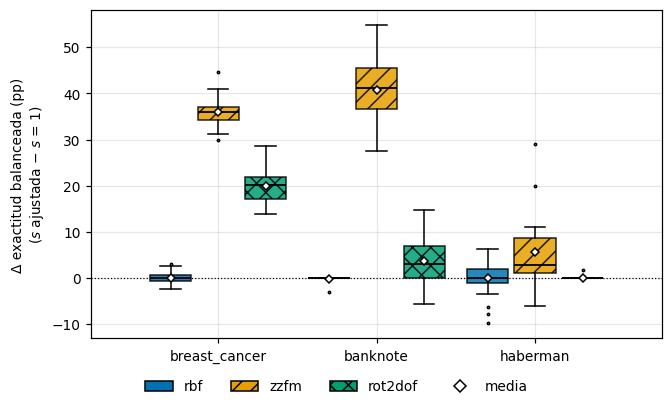

El kernel lineal no se muestra: no usa s y su diferencia es exactamente 0 en los 75 pares.


In [15]:
# --- Figura 4: diferencia (scale_tuned - kakavand) por kernel y dataset (25 pares semilla x pliegue) ---
KQ = ["rbf", "zzfm", "rot2dof"]
hat = {"rbf": "", "zzfm": "//", "rot2dof": "xx"}
fig, ax = plt.subplots(figsize=(6, 3.6), constrained_layout=True)
w = 0.26
for j, k in enumerate(KQ):
    data = [dd[(dd.dataset == d) & (dd.kernel == k)].delta_pp.values for d in DS]
    p = [i + (j - 1) * (w + 0.04) for i in range(len(DS))]
    bp = ax.boxplot(data, positions=p, widths=w, patch_artist=True, showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=4),
                    medianprops=dict(color="k", lw=1.2), flierprops=dict(marker=".", markersize=3))
    for b in bp["boxes"]:
        b.set_facecolor(kcol[k]); b.set_alpha(0.85); b.set_edgecolor("k"); b.set_hatch(hat[k])
ax.axhline(0, color="k", lw=0.8, ls=":")
ax.set_xticks(range(len(DS))); ax.set_xticklabels(DS)
ax.set_ylabel("Δ exactitud balanceada (pp)\n($s$ ajustada − $s$ = 1)")
hl = [Patch(facecolor=kcol[k], edgecolor="k", hatch=hat[k], label=k) for k in KQ] + \
     [Line2D([], [], marker="D", color="w", markerfacecolor="white", markeredgecolor="k", label="media")]
fig.legend(handles=hl, loc="outside lower center", ncol=4, frameon=False)
save_fig(fig, "fig4_efecto_s"); plt.show()
print("El kernel lineal no se muestra: no usa s y su diferencia es exactamente 0 en los 75 pares.")

## 7. Extensión de E1: n_c ∈ {7, 8} (modo `exact`)

**No forma parte del barrido original** (que se mantiene intacto: 144 corridas, n_c ≤ 6). Se agregó después de ver que
solo una combinación alcanzaba fidelidad ≥ 0.9: N ∈ {3, 7} × n_c ∈ {7, 8} × γ ∈ {0.1, 1, 10} × 3 semillas, solo `exact`
(36 corridas), con el mismo código y configuración del notebook 01 salvo la grilla de `n_c` y `mode`.
En la Figura 5 los puntos huecos y la zona sombreada son la extensión.

In [16]:
E1X_DIR = Path(os.environ.get("E1X_DIR", FINAL / "e1_ext_nc78"))
ext = pd.read_csv(E1X_DIR / "runs.csv")
assert len(ext) == 36 and not ext.duplicated(K1).any() and not ext[M1].isna().any().any()
assert set(ext["mode"]) == {"exact"} and set(ext.n_clock) == {7, 8}
ext["fid90"] = ext.fidelity >= 0.9
G1X = ["N", "n_clock", "gamma"]
aggx = ext.groupby(G1X)[E1_METRICS].agg(["median", "min", "max"])
aggx.columns = [f"{m}_{s}" for m, s in aggx.columns]; aggx = aggx.reset_index()
aggx.insert(3, "n_semillas", ext.groupby(G1X).seed.nunique().values)
aggx["semillas_fid90"] = ext.groupby(G1X).fid90.sum().values
aggx.to_csv(TABLES / "e1_ext_tabla_completa.csv", index=False)

def fmtx(r, m, d):
    if d == 0 and r[f"{m}_min"] == r[f"{m}_max"]:
        return f"{r[f'{m}_median']:.0f}"
    return f"{r[f'{m}_median']:.{d}f} [{r[f'{m}_min']:.{d}f}, {r[f'{m}_max']:.{d}f}]"

tx = pd.DataFrame({"N": aggx.N, "n_c": aggx.n_clock, "gamma": aggx.gamma.map(lambda g: f"{g:g}")})
for plain, m, d in [("kappa", "kappa", 1), ("fidelidad", "fidelity", 4), ("p_exito", "success_prob", 4),
                    ("acc_hhl", "acc_hhl", 2), ("concordancia", "agreement", 2), ("qubits", "n_total_qubits", 0),
                    ("prof_post", "depth_post", 0), ("cx", "cx_count", 0)]:
    tx[plain] = aggx.apply(lambda r: fmtx(r, m, d), axis=1)
tx["semillas fid>=0.9"] = aggx.semillas_fid90.astype(int).astype(str) + "/3"
write_table(tx, "e1_ext",
            tex_header=["$N$", "$n_c$", r"$\gamma$", r"$\kappa$", "fidelidad", r"$p_{\mathrm{\acute{e}xito}}$", "acc. HHL",
                        "concordancia", "qubits", "profundidad (transp.)", "cx", r"semillas $F\geq0.9$"],
            align="ccccccccccc" + "c")
print(f"Extensión: corridas con fidelidad >= 0.9: {int(ext.fid90.sum())} de {len(ext)}")
print(ext.pivot_table(index=["N", "gamma"], columns="n_clock", values="fid90", aggfunc="sum").to_string())
tx

tabla: e1_ext (12, 12)
Extensión: corridas con fidelidad >= 0.9: 16 de 36
n_clock  7  8
N gamma      
3 0.1    0  0
  1.0    3  3
  10.0   3  3
7 0.1    0  0
  1.0    1  3
  10.0   0  0


,N,n_c,gamma,kappa,fidelidad,p_exito,acc_hhl,concordancia,qubits,prof_post,cx,semillas fid>=0.9
0,3,7,0.1,"273.7 [236.3, 282.8]","0.0563 [0.0539, 0.0808]","0.0019 [0.0015, 0.0020]","0.80 [0.65, 0.85]","0.97 [0.93, 1.00]",10,24869,10403,0/3
1,3,7,1,"54.3 [46.0, 56.4]","0.9993 [0.9984, 1.0000]","0.0528 [0.0334, 0.0551]","0.82 [0.65, 0.88]","1.00 [1.00, 1.00]",10,24869,10403,3/3
2,3,7,10,"41.5 [35.1, 43.1]","0.9993 [0.9991, 0.9996]","0.0359 [0.0277, 0.0410]","0.82 [0.65, 0.88]","1.00 [1.00, 1.00]",10,24869,10403,3/3
3,3,8,0.1,"273.7 [236.3, 282.8]","0.5779 [0.5287, 0.7930]","0.0008 [0.0008, 0.0010]","0.80 [0.65, 0.85]","0.97 [0.93, 1.00]",11,57969,26817,0/3
4,3,8,1,"54.3 [46.0, 56.4]","0.9994 [0.9994, 1.0000]","0.0122 [0.0074, 0.0132]","0.82 [0.65, 0.88]","1.00 [1.00, 1.00]",11,57969,26817,3/3
5,3,8,10,"41.5 [35.1, 43.1]","0.9999 [0.9994, 1.0000]","0.0119 [0.0074, 0.0123]","0.82 [0.65, 0.88]","1.00 [1.00, 1.00]",11,57969,26817,3/3
6,7,7,0.1,"200.8 [197.3, 231.7]","0.4753 [0.4316, 0.6826]","0.0115 [0.0084, 0.0215]","0.93 [0.93, 0.97]","1.00 [0.93, 1.00]",11,"27203 [27202, 27206]",10994,0/3
7,7,7,1,"122.9 [120.6, 143.2]","0.8401 [0.5868, 0.9245]","0.0423 [0.0275, 0.0925]","0.93 [0.93, 0.97]","1.00 [1.00, 1.00]",11,"27203 [27202, 27206]",10994,1/3
8,7,7,10,"1219.9 [1197.3, 1423.0]","0.0002 [0.0001, 0.0002]","0.0110 [0.0107, 0.0186]","0.93 [0.93, 0.97]","1.00 [1.00, 1.00]",11,"27203 [27202, 27206]",10994,0/3
9,7,8,0.1,"200.8 [197.3, 231.7]","0.8413 [0.6960, 0.8840]","0.0030 [0.0026, 0.0060]","0.93 [0.93, 1.00]","1.00 [0.95, 1.00]",12,"60659 [60658, 60662]",27492,0/3


figura: fig5_fidelidad_vs_nc_extendida


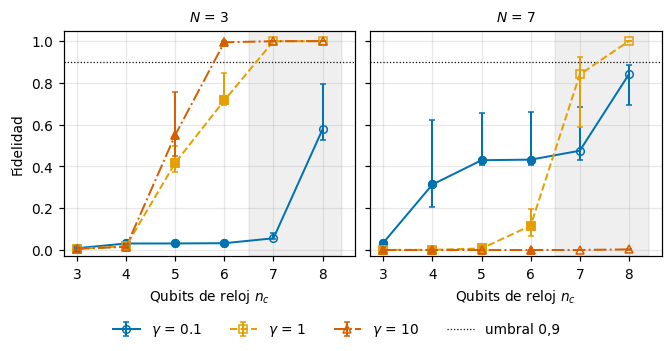

In [17]:
# --- Figura 5: fidelidad vs n_c (3..8), modo exact; punto relleno = barrido original, hueco = extensión ---
both = pd.concat([e1[e1["mode"] == "exact"], ext], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(6, 3.1), sharey=True, constrained_layout=True)
for ax, N in zip(axes, [3, 7]):
    for i, g in enumerate(sorted(both.gamma.unique())):
        s = both[(both.N == N) & (both.gamma == g)].groupby("n_clock").fidelity.agg(["median", "min", "max"])
        st_ = sty[i % len(sty)]
        ax.errorbar(s.index, s["median"], yerr=[s["median"] - s["min"], s["max"] - s["median"]], capsize=2, lw=1.3, ms=5,
                    label=rf"$\gamma$ = {g:g}", mfc="none", mec=st_["color"], **st_)
        so = s[s.index <= 6]
        ax.plot(so.index, so["median"], ls="none", marker=st_["marker"], ms=5, color=st_["color"])
    ax.axvspan(6.5, 8.4, color="gray", alpha=0.12)
    ax.axhline(0.9, color="k", lw=0.8, ls=":")
    ax.set_title(rf"$N$ = {N}"); ax.set_xlabel(r"Qubits de reloj $n_c$"); ax.set_xticks(range(3, 9)); ax.set_ylim(-0.03, 1.05)
axes[0].set_ylabel("Fidelidad")
h, l = axes[0].get_legend_handles_labels()
h.append(Line2D([], [], color="k", lw=0.8, ls=":")); l.append("umbral 0,9")
fig.legend(h, l, loc="outside lower center", ncol=len(h), frameon=False)
save_fig(fig, "fig5_fidelidad_vs_nc_extendida"); plt.show()

## 8. E1 con ruido (N = 3, modo `exact`)

Barrido **adicional y posterior** al original: N = 3, n_c ∈ {3, 4, 5, 6}, γ ∈ {0.1, 1, 10}, 3 semillas, solo `exact` (36 corridas),
con `NOISE = True` en el notebook 01: Aer con matriz de densidad, depolarizante 1q = 0.001 (en `sx`) y 2q = 0.01 (en `cx`).
`fidelity` es la sin ruido (igual al barrido original); `fidelity_noisy` y `success_prob_noisy` son las de la simulación con ruido.
El modo `trotter` con ruido no se ejecutó.

In [18]:
E1N_DIR = Path(os.environ.get("E1N_DIR", FINAL / "e1_noise_exact"))
nz = pd.read_csv(E1N_DIR / "runs.csv")
assert len(nz) == 36 and not nz.duplicated(K1).any()
assert not nz[M1 + ["fidelity_noisy", "success_prob_noisy"]].isna().any().any()
assert set(nz.N) == {3} and set(nz["mode"]) == {"exact"}
# la parte sin ruido debe coincidir con el barrido original (mismas corridas)
ref = e1[(e1.N == 3) & (e1["mode"] == "exact")].set_index(K1).fidelity
assert np.allclose(nz.set_index(K1).fidelity.sort_index(), ref.sort_index()), "fidelidad sin ruido difiere del barrido original"
GN = ["gamma", "n_clock"]
NM = ["kappa", "fidelity", "fidelity_noisy", "success_prob", "success_prob_noisy"]
an = nz.groupby(GN)[NM].agg(["median", "min", "max"])
an.columns = [f"{m}_{s}" for m, s in an.columns]; an = an.reset_index()
an.to_csv(TABLES / "e1_ruido_tabla_completa.csv", index=False)
def f3(r, m, d):
    return f"{r[f'{m}_median']:.{d}f} [{r[f'{m}_min']:.{d}f}, {r[f'{m}_max']:.{d}f}]"
tn = pd.DataFrame({"gamma": an.gamma.map(lambda g: f"{g:g}"), "n_c": an.n_clock})
for plain, m, d in [("fidelidad sin ruido", "fidelity", 3), ("fidelidad con ruido", "fidelity_noisy", 3),
                    ("p_exito sin ruido", "success_prob", 4), ("p_exito con ruido", "success_prob_noisy", 4)]:
    tn[plain] = an.apply(lambda r: f3(r, m, d), axis=1)
write_table(tn, "e1_ruido", tex_header=[r"$\gamma$", "$n_c$", "fidelidad sin ruido", "fidelidad con ruido",
            r"$p_{\mathrm{\acute{e}xito}}$ sin ruido", r"$p_{\mathrm{\acute{e}xito}}$ con ruido"], align="ccllll")
print("fidelidad con ruido: mín", nz.fidelity_noisy.min(), "máx", nz.fidelity_noisy.max(), "| corridas con >= 0.9:", int((nz.fidelity_noisy >= 0.9).sum()))
print("cambio por el ruido (fidelidad_noisy - fidelidad), mediana por n_c:")
print((nz.fidelity_noisy - nz.fidelity).groupby(nz.n_clock).median().round(3).to_string())
print("cómputo total (s):", nz.wall_time_s.sum())
tn

tabla: e1_ruido (12, 6)
fidelidad con ruido: mín 0.0671864181691926 máx 0.1954327744001951 | corridas con >= 0.9: 0
cambio por el ruido (fidelidad_noisy - fidelidad), mediana por n_c:
n_clock
3    0.070
4    0.088
5   -0.248
6   -0.524
cómputo total (s): 85.94638109207153


,gamma,n_c,fidelidad sin ruido,fidelidad con ruido,p_exito sin ruido,p_exito con ruido
0,0.1,3,"0.009 [0.008, 0.013]","0.075 [0.067, 0.080]","0.1086 [0.1036, 0.1190]","0.1107 [0.1096, 0.1134]"
1,0.1,4,"0.031 [0.031, 0.033]","0.115 [0.113, 0.119]","0.1201 [0.1190, 0.1252]","0.0553 [0.0551, 0.0558]"
2,0.1,5,"0.032 [0.031, 0.033]","0.160 [0.159, 0.169]","0.0308 [0.0278, 0.0313]","0.0170 [0.0170, 0.0171]"
3,0.1,6,"0.033 [0.033, 0.035]","0.191 [0.181, 0.194]","0.0077 [0.0056, 0.0078]","0.0078 [0.0078, 0.0078]"
4,1,3,"0.006 [0.005, 0.007]","0.077 [0.076, 0.078]","0.1000 [0.0994, 0.1093]","0.1115 [0.1091, 0.1118]"
5,1,4,"0.018 [0.017, 0.035]","0.117 [0.117, 0.118]","0.0189 [0.0185, 0.0225]","0.0531 [0.0530, 0.0533]"
6,1,5,"0.417 [0.375, 0.496]","0.170 [0.169, 0.174]","0.0134 [0.0129, 0.0236]","0.0169 [0.0169, 0.0169]"
7,1,6,"0.716 [0.694, 0.845]","0.194 [0.192, 0.195]","0.0806 [0.0782, 0.0821]","0.0078 [0.0078, 0.0078]"
8,10,3,"0.006 [0.005, 0.008]","0.076 [0.075, 0.076]","0.1001 [0.0994, 0.1080]","0.1109 [0.1091, 0.1114]"
9,10,4,"0.015 [0.015, 0.029]","0.115 [0.114, 0.116]","0.0186 [0.0184, 0.0226]","0.0530 [0.0529, 0.0535]"


In [19]:
print("Tablas:", sorted(p.name for p in TABLES.iterdir()))
print("Figuras:", sorted(p.name for p in FIGS.iterdir()))

Tablas: ['e1_calidad.csv', 'e1_calidad.tex', 'e1_ext.csv', 'e1_ext.tex', 'e1_ext_tabla_completa.csv', 'e1_fid90_por_config.csv', 'e1_recursos.csv', 'e1_recursos.tex', 'e1_ruido.csv', 'e1_ruido.tex', 'e1_ruido_tabla_completa.csv', 'e1_tabla_completa.csv', 'e2_best_s.csv', 'e2_best_s.tex', 'e2_best_s_conteos.csv', 'e2_costo.csv', 'e2_costo.tex', 'e2_costo_numerico.csv', 'e2_efecto_s.csv', 'e2_efecto_s.tex', 'e2_efecto_s_numerico.csv', 'e2_pareada.csv', 'e2_pareada.tex', 'e2_pareada_numerico.csv', 'e2_principal.csv', 'e2_principal.tex', 'e2_principal_numerico.csv']
Figuras: ['fig1_fidelidad_vs_nc.pdf', 'fig1_fidelidad_vs_nc.png', 'fig2_cx_vs_nc.pdf', 'fig2_cx_vs_nc.png', 'fig3_boxplot_balanced_accuracy.pdf', 'fig3_boxplot_balanced_accuracy.png', 'fig4_efecto_s.pdf', 'fig4_efecto_s.png', 'fig5_fidelidad_vs_nc_extendida.pdf', 'fig5_fidelidad_vs_nc_extendida.png']
